# Семинар 12, часть 1. Метод главных компонент (PCA)

Обрабатывать сотни и тысячи признаков трудно, а нарисовать их невозможно. Метод главных компонент (PCA) переходит к меньшему числу новых признаков — линейных комбинаций исходных — и старается потерять как можно меньше информации.

Зачем это нужно:

- **Визуализация.** Спроецировав данные на 2–3 компоненты, их можно нарисовать на плоскости.
- **Сжатие.** Меньше признаков — меньше памяти и быстрее обучение моделей.
- **Шумоподавление.** Шум размазан по всем направлениям, а сигнал сосредоточен в нескольких главных; отбросив младшие компоненты, мы отбрасываем в основном шум.
- **Борьба с проклятием размерности.** В пространствах высокой размерности расстояния между точками становятся похожими друг на друга: отношение расстояний до ближайшей и до самой далёкой точки стремится к единице. Методам на расстояниях (kNN, K-means) от этого хуже.

План:

1. PCA своими руками на шести точках: стандартизация, матрица ковариаций, собственные векторы, проекция, восстановление.
2. PCA на Iris: интерпретация компонент.
3. Digits: визуализация, выбор числа компонент, сжатие изображений.
4. Шумоподавление.
5. Когда PCA вредит: метод не видит целевую переменную.
6. Нелинейные данные.
7. Визуализация слов.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 1. PCA своими руками

### 1.1 Данные

Возьмём шесть точек с двумя признаками и выполним все шаги PCA вручную.

In [2]:
df = pd.DataFrame({'x1': [9, 7, 3, 5, 2, 2], 'x2': [7, 5, 7, 6, 3, 1]})
df

,x1,x2
0,9,7
1,7,5
2,3,7
3,5,6
4,2,3
5,2,1


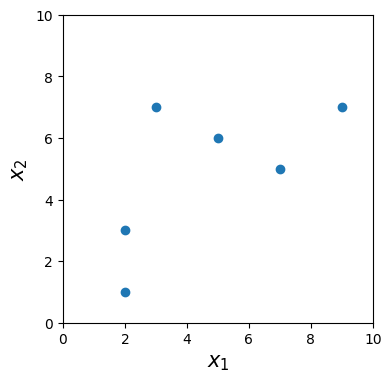

In [3]:
plt.figure(figsize=(4, 4))
plt.scatter(df['x1'], df['x2'], zorder=5)
plt.xlim(0, 10); plt.ylim(0, 10)
plt.xlabel('$x_1$', fontsize=15); plt.ylabel('$x_2$', fontsize=15)
plt.show()

### 1.2 Стандартизация

Вычтем из каждого признака среднее и поделим на стандартное отклонение. Центрирование для PCA обязательно: компоненты — это направления разброса **вокруг центра** данных. Деление на стандартное отклонение нужно, когда признаки измерены в разных единицах.

In [4]:
Z = StandardScaler().fit_transform(df.to_numpy())
Z.round(3)

array([[ 1.651,  0.988],
       [ 0.889,  0.076],
       [-0.635,  0.988],
       [ 0.127,  0.532],
       [-1.016, -0.836],
       [-1.016, -1.749]])

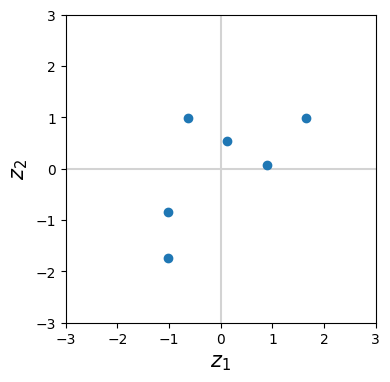

In [5]:
plt.figure(figsize=(4, 4))
plt.scatter(Z[:, 0], Z[:, 1], zorder=5)
plt.axhline(0, color='lightgray'); plt.axvline(0, color='lightgray')
plt.xlim(-3, 3); plt.ylim(-3, 3)
plt.xlabel('$z_1$', fontsize=15); plt.ylabel('$z_2$', fontsize=15)
plt.show()

### 1.3 Матрица ковариаций

$$
C = \frac{1}{n} Z^T Z .
$$

Параметр `ddof=0` означает деление на $n$, а не на $n-1$; на направления компонент это не влияет.

In [6]:
n = len(Z)
C = Z.T @ Z / n
print(C.round(4))
print('То же через np.cov:', np.allclose(C, np.cov(Z, rowvar=False, ddof=0)))

[[1.     0.6276]
 [0.6276 1.    ]]
То же через np.cov: True


После стандартизации дисперсии признаков равны 1, и матрица ковариаций совпадает с матрицей корреляций: 0,628 — корреляция между $x_1$ и $x_2$.

### 1.4 Собственные векторы

Для симметричной матрицы используем `np.linalg.eigh`: она быстрее и точнее, чем общая `eig`, и гарантирует вещественный результат. Собственные числа она возвращает **по возрастанию**, поэтому переставим их по убыванию: первая компонента — с наибольшей дисперсией.

In [7]:
eig_values, eig_vectors = np.linalg.eigh(C)   # собственные векторы — в столбцах
order = np.argsort(eig_values)[::-1]
eig_values = eig_values[order]
W = eig_vectors[:, order]                       # столбец k — k-я главная компонента

print('Собственные числа:', eig_values.round(4))
print('Матрица W (компоненты в столбцах):')
print(W.round(4))
print('Длины векторов:', np.linalg.norm(W, axis=0))

Собственные числа: [1.6276 0.3724]
Матрица W (компоненты в столбцах):
[[-0.7071  0.7071]
 [-0.7071 -0.7071]]
Длины векторов: [1. 1.]


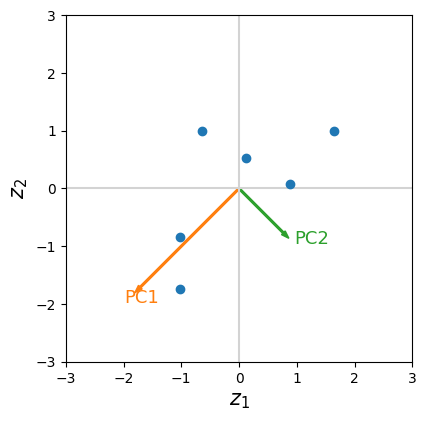

In [8]:
plt.figure(figsize=(4.5, 4.5))
plt.scatter(Z[:, 0], Z[:, 1], zorder=5)
for k, color in zip(range(2), ['C1', 'C2']):
    vec = W[:, k] * np.sqrt(eig_values[k]) * 2      # длина стрелки ~ стандартное отклонение
    plt.arrow(0, 0, *vec, width=0.03, color=color, length_includes_head=True)
    plt.text(*(vec * 1.1), f'PC{k + 1}', color=color, fontsize=13)
plt.axhline(0, color='lightgray'); plt.axvline(0, color='lightgray')
plt.xlim(-3, 3); plt.ylim(-3, 3); plt.gca().set_aspect('equal')
plt.xlabel('$z_1$', fontsize=15); plt.ylabel('$z_2$', fontsize=15)
plt.show()

Первая компонента направлена вдоль диагонали $(1, 1)/\sqrt{2}$ (`eigh` вернул её со знаком минус — знак произволен, см. раздел 1.8) — туда, куда вытянуто облако точек. Вторая перпендикулярна ей. Для двух стандартизованных признаков так будет всегда: собственные векторы матрицы $\begin{pmatrix} 1 & r \\ r & 1 \end{pmatrix}$ равны $(1, 1)/\sqrt{2}$ и $(-1, 1)/\sqrt{2}$ при любой корреляции $r$, а собственные числа — $1 + r$ и $1 - r$. Проверьте: $1 + 0{,}628 = 1{,}628$.

### 1.5 Проекция на главные компоненты

Новые координаты точек — скалярные произведения на векторы компонент: $T = ZW$.

In [9]:
T = Z @ W
T.round(3)

array([[-1.866,  0.469],
       [-0.682,  0.575],
       [-0.25 , -1.148],
       [-0.466, -0.287],
       [ 1.31 , -0.127],
       [ 1.955,  0.518]])

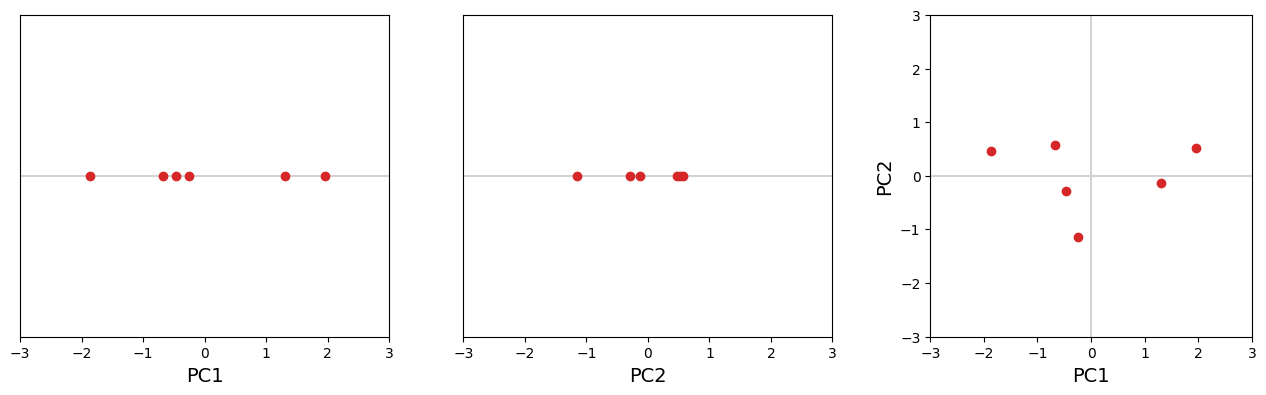

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].scatter(T[:, 0], np.zeros(n), color='C3', zorder=5); axes[0].set_xlabel('PC1', fontsize=14)
axes[1].scatter(T[:, 1], np.zeros(n), color='C3', zorder=5); axes[1].set_xlabel('PC2', fontsize=14)
axes[2].scatter(T[:, 0], T[:, 1], color='C3', zorder=5)
axes[2].set_xlabel('PC1', fontsize=14); axes[2].set_ylabel('PC2', fontsize=14); axes[2].set_aspect('equal')
for ax in axes:
    ax.axhline(0, color='lightgray'); ax.set_xlim(-3, 3)
axes[2].axvline(0, color='lightgray'); axes[2].set_ylim(-3, 3)
for ax in axes[:2]:
    ax.set_yticks([])
plt.tight_layout(); plt.show()

Справа те же точки в новых координатах: облако «повернулось» так, что его длинная ось легла на горизонталь. Вдоль PC1 точки разбросаны сильно, вдоль PC2 — слабо.

### 1.6 Дисперсия вдоль компонент и доля объяснённой дисперсии

In [11]:
var_along = (T ** 2).sum(axis=0) / n     # среднее точек вдоль компонент равно 0
print('Дисперсия проекций:', var_along.round(4))
print('Собственные числа:  ', eig_values.round(4))

Дисперсия проекций: [1.6276 0.3724]
Собственные числа:   [1.6276 0.3724]


Доля объяснённой дисперсии: [0.8138 0.1862]


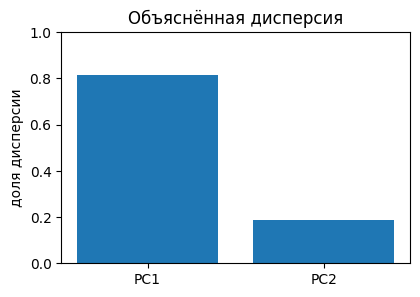

In [12]:
ratio = eig_values / eig_values.sum()
print('Доля объяснённой дисперсии:', ratio.round(4))

plt.figure(figsize=(4.5, 3))
plt.bar(['PC1', 'PC2'], ratio)
plt.ylim(0, 1); plt.ylabel('доля дисперсии'); plt.title('Объяснённая дисперсия')
plt.show()

**Вопрос.** Почему дисперсия проекций на первую компоненту в точности равна первому собственному числу?

<details>
<summary><b>Показать ответ</b></summary>

Дисперсия проекций на единичный вектор $v$ равна $v^T C v$ (так начинался вывод на лекции). Если $v$ — собственный вектор, то $Cv = \lambda v$, и $v^T C v = \lambda\, v^T v = \lambda$, потому что $\lVert v \rVert = 1$. Поэтому собственное число — это дисперсия вдоль своей компоненты, а доля объяснённой дисперсии — $\lambda_k / \sum_j \lambda_j$. Здесь первая компонента объясняет 81,4 % дисперсии.

</details>

### 1.7 Восстановление точек

Матрица $W$ ортогональна ($W^T W = I$), поэтому из всех компонент точки восстанавливаются без потерь: $Z = T W^T$. Если оставить только первую компоненту, восстановленные точки лягут на прямую PC1.

In [13]:
Z_full = T @ W.T
print('Полное восстановление точное:', np.allclose(Z_full, Z))

Z_1 = T[:, :1] @ W[:, :1].T      # только первая компонента
Z_1.round(3)

Полное восстановление точное: True


array([[ 1.32 ,  1.32 ],
       [ 0.483,  0.483],
       [ 0.177,  0.177],
       [ 0.33 ,  0.33 ],
       [-0.926, -0.926],
       [-1.382, -1.382]])

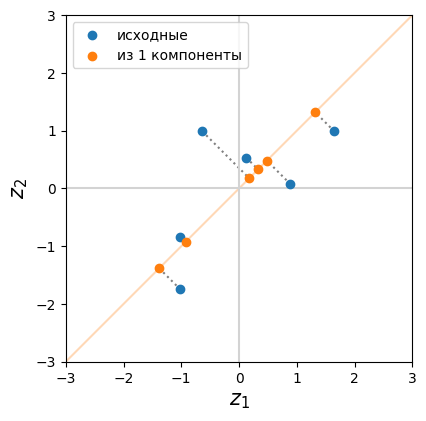

Средний квадрат ошибки восстановления: 0.3724


In [14]:
plt.figure(figsize=(4.5, 4.5))
plt.scatter(Z[:, 0], Z[:, 1], label='исходные', zorder=5)
plt.scatter(Z_1[:, 0], Z_1[:, 1], label='из 1 компоненты', zorder=5)
for a, b in zip(Z, Z_1):
    plt.plot([a[0], b[0]], [a[1], b[1]], color='gray', ls=':')
plt.plot([-3, 3], np.array([-3, 3]) * W[1, 0] / W[0, 0], color='C1', alpha=0.3)
plt.axhline(0, color='lightgray'); plt.axvline(0, color='lightgray')
plt.xlim(-3, 3); plt.ylim(-3, 3); plt.gca().set_aspect('equal'); plt.legend()
plt.xlabel('$z_1$', fontsize=15); plt.ylabel('$z_2$', fontsize=15)
plt.show()
print('Средний квадрат ошибки восстановления:', round(((Z - Z_1) ** 2).sum() / n, 4))

**Вопрос.** Чему равна ошибка восстановления по одной компоненте и как она связана с собственными числами?

<details>
<summary><b>Показать ответ</b></summary>

Потеряна ровно вторая координата каждой точки — её проекция на PC2 (пунктиры на графике перпендикулярны прямой PC1). Поэтому средний квадрат ошибки — это дисперсия вдоль PC2, то есть второе собственное число: 0,372. В общем случае, отбросив компоненты $k+1, \dots, d$, мы теряем $\lambda_{k+1} + \dots + \lambda_d$ — сумму отброшенных собственных чисел. Максимум сохранённой дисперсии ⇔ минимум суммы квадратов расстояний до подпространства.

</details>

### 1.8 Сверим со sklearn

In [15]:
pca = PCA()
T_sk = pca.fit_transform(Z)
print('Компоненты sklearn (в строках):')
print(pca.components_.round(4))
print('Доли дисперсии:', pca.explained_variance_ratio_.round(4))
print('Проекции совпадают с точностью до знака:', np.allclose(np.abs(T_sk), np.abs(T)))

Компоненты sklearn (в строках):
[[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]
Доли дисперсии: [0.8138 0.1862]
Проекции совпадают с точностью до знака: True


Обратите внимание: в `sklearn` компоненты лежат в **строках** `components_`, а у нас — в столбцах `W`.

**Вопрос.** Знак какой-то компоненты у sklearn может отличаться от нашего. Ошибка ли это?

<details>
<summary><b>Показать ответ</b></summary>

Нет. Если $v$ — собственный вектор, то и $-v$ тоже: $C(-v) = \lambda(-v)$. Направление «вдоль прямой» одно, а стрелку на ней можно повернуть в любую сторону. Проекции при смене знака компоненты тоже меняют знак, но разброс, доля дисперсии и восстановленные точки не меняются. Поэтому при интерпретации компонент смотрят на относительные знаки весов внутри одной компоненты, а не на общий знак.

</details>

## 2. PCA на Iris

Четыре признака цветков ириса (длина и ширина чашелистика и лепестка, в сантиметрах), 150 цветков трёх видов. Признаки в одних единицах, но их разброс сильно различается, поэтому стандартизуем.

In [16]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target_names[iris.target]
X_iris.describe().loc[['mean', 'std']].round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76


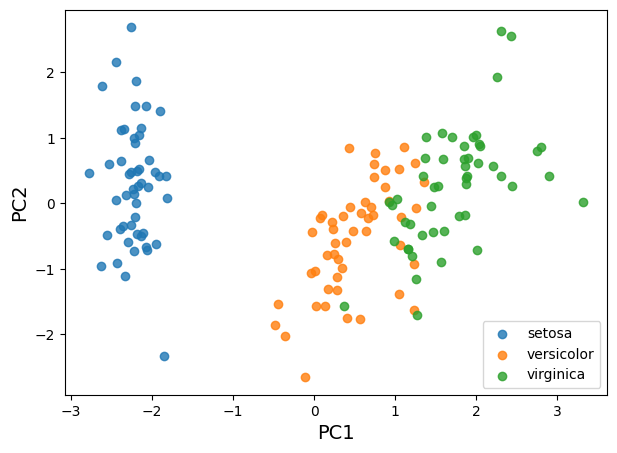

Доли дисперсии: [0.73  0.229]  в сумме: 0.958


In [17]:
pca_iris = PCA(n_components=2)
T_iris = pca_iris.fit_transform(StandardScaler().fit_transform(X_iris))

plt.figure(figsize=(7, 5))
for name in iris.target_names:
    m = y_iris == name
    plt.scatter(T_iris[m, 0], T_iris[m, 1], label=name, alpha=0.8)
plt.xlabel('PC1', fontsize=14); plt.ylabel('PC2', fontsize=14); plt.legend()
plt.show()
print('Доли дисперсии:', pca_iris.explained_variance_ratio_.round(3),
      ' в сумме:', pca_iris.explained_variance_ratio_.sum().round(3))

In [18]:
loadings = pd.DataFrame(pca_iris.components_, columns=X_iris.columns, index=['PC1', 'PC2']).round(2)
loadings

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
PC1,0.52,-0.27,0.58,0.56
PC2,0.38,0.92,0.02,0.07


Две компоненты сохраняют 95,8 % дисперсии четырёх признаков. Виды хорошо видны на плоскости: setosa отделена полностью, versicolor и virginica немного перекрываются.

**Вопрос.** Как интерпретировать PC1 и PC2 по таблице весов?

<details>
<summary><b>Показать ответ</b></summary>

В PC1 большие веса одного знака у длины чашелистика (0,52), длины лепестка (0,58) и ширины лепестка (0,56), а у ширины чашелистика вес небольшой и противоположного знака (−0,27). PC1 — это «общий размер цветка, прежде всего лепестка»: чем больше PC1, тем крупнее лепестки. Именно по размеру лепестков setosa отличается от остальных видов, поэтому она отделена по горизонтали.

В PC2 почти весь вес у ширины чашелистика (0,92). PC2 — это «ширина чашелистика», не связанная с общим размером. Интерпретация удалась, потому что признаков мало и они осмысленные; на сотнях признаков компоненты обычно читаются гораздо хуже.

</details>

## 3. Digits: визуализация и сжатие

1797 изображений рукописных цифр размером 8 × 8 пикселей, то есть 64 признака — яркости пикселей от 0 до 16.

In [19]:
from sklearn.datasets import load_digits

digits = load_digits()
X_dig, y_dig = digits.data, digits.target
X_dig.shape

(1797, 64)

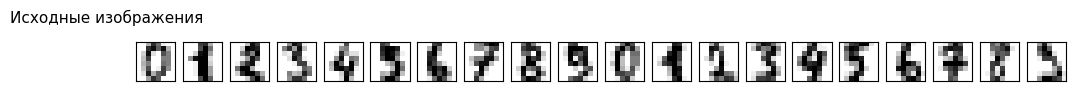

In [20]:
def show_digits(images, title=None, n=20):
    """Первые n изображений одной строкой."""
    fig, axes = plt.subplots(1, n, figsize=(n * 0.6, 0.8),
                             subplot_kw={'xticks': [], 'yticks': []})
    for ax, img in zip(axes, images):
        ax.imshow(img.reshape(8, 8), cmap='binary', vmin=0, vmax=16)
    if title:
        fig.suptitle(title, x=0.02, ha='left', fontsize=11, y=1.15)
    plt.show()

show_digits(X_dig, 'Исходные изображения')

### 3.1 Визуализация на плоскости

Пиксели измерены в одних единицах, поэтому масштабировать их не обязательно. Сравним два варианта: PCA только с центрированием (его `PCA` делает сам) и PCA после `StandardScaler`.

Две компоненты объясняют без масштабирования: 0.285
Две компоненты объясняют после StandardScaler:  0.216


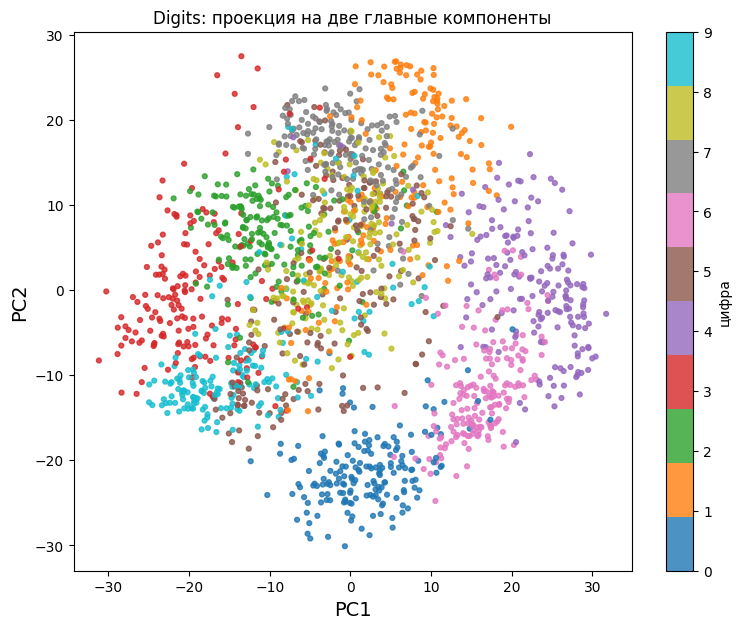

In [21]:
pca_raw = PCA(n_components=2).fit(X_dig)
pca_std = PCA(n_components=2).fit(StandardScaler().fit_transform(X_dig))
print('Две компоненты объясняют без масштабирования:', pca_raw.explained_variance_ratio_.sum().round(3))
print('Две компоненты объясняют после StandardScaler: ', pca_std.explained_variance_ratio_.sum().round(3))

T_dig = pca_raw.transform(X_dig)
plt.figure(figsize=(9, 7))
sc = plt.scatter(T_dig[:, 0], T_dig[:, 1], c=y_dig, cmap='tab10', s=12, alpha=0.8)
plt.colorbar(sc, ticks=range(10), label='цифра')
plt.xlabel('PC1', fontsize=14); plt.ylabel('PC2', fontsize=14)
plt.title('Digits: проекция на две главные компоненты')
plt.show()

Некоторые цифры (0, 4, 6) образуют заметные группы, но многие сильно перекрываются: две компоненты сохраняют меньше трети дисперсии. Для визуализации таких данных лучше подходят нелинейные методы — t-SNE во второй части семинара.

**Вопрос.** Почему после стандартизации две компоненты объясняют меньшую долю дисперсии (21,6 % против 28,5 %)? Стоит ли стандартизовать пиксели?

<details>
<summary><b>Показать ответ</b></summary>

`StandardScaler` делит каждый пиксель на его стандартное отклонение. У пикселей по краям картинки почти всегда 0, и их крошечный разброс после деления раздувается до единицы — наравне с информативными пикселями в центре. Получается 64 признака одинаковой дисперсии, из которых многие почти шумовые, и общая дисперсия «размазывается» по большему числу направлений. Без масштабирования краевые пиксели почти не влияют на компоненты, а дисперсия сосредоточена в осмысленных направлениях.

Стандартизация нужна, когда признаки измерены в разных единицах. Пиксели — в одних, и их разброс содержателен, поэтому для изображений обычно ограничиваются центрированием.

</details>

### 3.2 Сколько компонент оставить

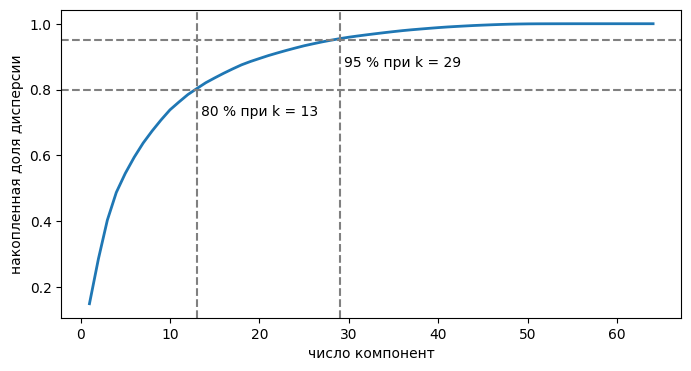

80 % дисперсии: 13 компонент;  95 %: 29 компонент из 64


In [22]:
pca_full = PCA().fit(X_dig)
cum = np.cumsum(pca_full.explained_variance_ratio_)
k80 = np.argmax(cum >= 0.80) + 1
k95 = np.argmax(cum >= 0.95) + 1

plt.figure(figsize=(8, 4))
plt.plot(range(1, 65), cum, lw=2)
for k, p in [(k80, 0.80), (k95, 0.95)]:
    plt.axhline(p, ls='--', color='gray'); plt.axvline(k, ls='--', color='gray')
    plt.text(k + 0.5, p - 0.08, f'{int(p * 100)} % при k = {k}')
plt.xlabel('число компонент'); plt.ylabel('накопленная доля дисперсии')
plt.show()
print('80 % дисперсии:', k80, 'компонент;  95 %:', k95, 'компонент из 64')

Здесь `PCA(n_components=0.95)` выбрал бы число компонент сам: дробное значение `n_components` в `sklearn` означает долю дисперсии.

### 3.3 Сжатие изображений

Спроецируем цифры на первые $k$ компонент и восстановим обратно методом `inverse_transform`: он умножает проекции на компоненты и прибавляет среднее.

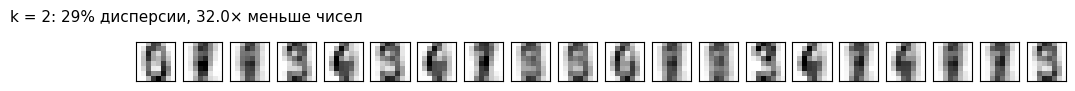

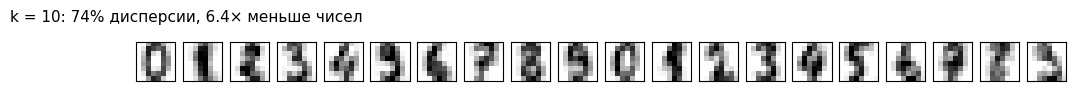

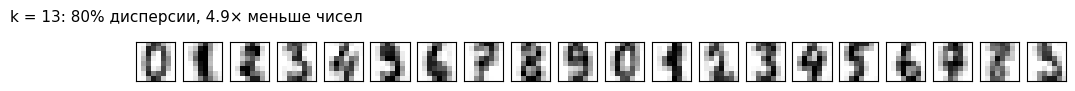

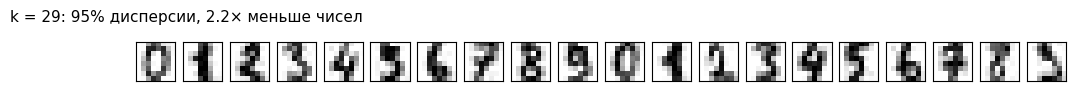

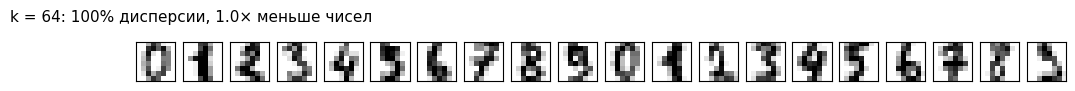

In [23]:
for k in [2, 10, k80, k95, 64]:
    pca_k = PCA(n_components=k).fit(X_dig)
    restored = pca_k.inverse_transform(pca_k.transform(X_dig))
    share = pca_k.explained_variance_ratio_.sum()
    show_digits(restored, f'k = {k}: {share:.0%} дисперсии, {64 / k:.1f}× меньше чисел')

При $k = 2$ все цифры похожи на размытое пятно, при $k = 10$ большинство уже узнаётся, при $k = 29$ (95 % дисперсии) восстановление почти неотличимо от оригинала, хотя чисел в 2,2 раза меньше. При $k = 64$ восстановление точное.

**Вопрос.** Сколько чисел на самом деле нужно хранить, чтобы восстановить изображения по $k$ компонентам?

<details>
<summary><b>Показать ответ</b></summary>

Для каждого изображения — $k$ проекций. Плюс один раз на весь набор: $k$ векторов компонент по 64 числа и вектор среднего из 64 чисел. При $k = 29$ это $1797 \cdot 29 + 29 \cdot 64 + 64 \approx 54{,}0$ тыс. чисел против $1797 \cdot 64 \approx 115$ тыс. Накладные расходы на компоненты малы, когда объектов много.

</details>

## 4. Шумоподавление

Добавим к цифрам сильный гауссовский шум и попробуем его убрать: обучим PCA на зашумлённых данных, оставим $k$ компонент и восстановим. Чистые изображения у нас есть, поэтому качество можно измерить — среднеквадратичной ошибкой (MSE) между восстановлением и **чистыми** цифрами.

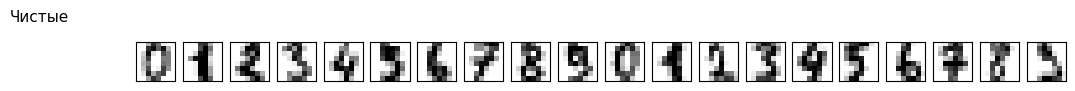

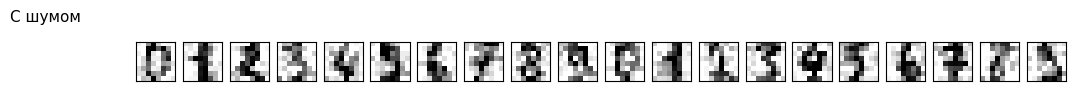

In [24]:
rng = np.random.default_rng(42)
X_noisy = X_dig + rng.normal(0, 3, size=X_dig.shape)   # стандартное отклонение шума — 3

show_digits(X_dig, 'Чистые')
show_digits(X_noisy, 'С шумом')

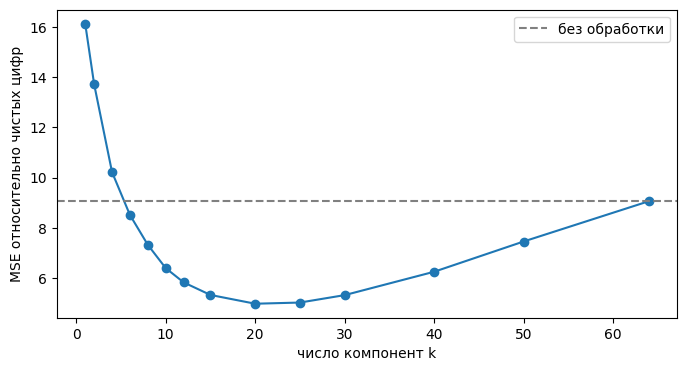

Лучшее k: 20  MSE: 4.98  MSE без обработки: 9.06


In [25]:
ks = [1, 2, 4, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 64]
mse = []
for k in ks:
    pca_k = PCA(n_components=k).fit(X_noisy)
    restored = pca_k.inverse_transform(pca_k.transform(X_noisy))
    mse.append(((restored - X_dig) ** 2).mean())
best_k = ks[int(np.argmin(mse))]

plt.figure(figsize=(8, 4))
plt.plot(ks, mse, 'o-')
plt.axhline(((X_noisy - X_dig) ** 2).mean(), color='gray', ls='--', label='без обработки')
plt.xlabel('число компонент k'); plt.ylabel('MSE относительно чистых цифр')
plt.legend(); plt.show()
print('Лучшее k:', best_k, ' MSE:', round(min(mse), 2), ' MSE без обработки:', round(((X_noisy - X_dig) ** 2).mean(), 2))

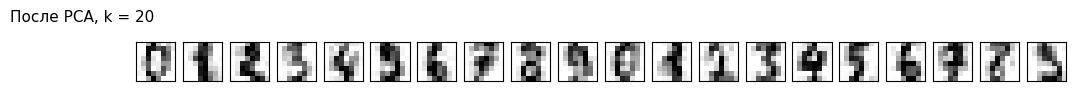

In [26]:
pca_best = PCA(n_components=best_k).fit(X_noisy)
show_digits(pca_best.inverse_transform(pca_best.transform(X_noisy)), f'После PCA, k = {best_k}')

**Вопрос.** Почему ошибка сначала падает с ростом $k$, а потом растёт? Почему при $k = 64$ она равна ошибке без обработки?

<details>
<summary><b>Показать ответ</b></summary>

Сигнал (сами цифры) сосредоточен в нескольких главных направлениях, а шум — независимый в каждом пикселе — размазан равномерно по всем 64 направлениям. Первые компоненты добавляют в основном сигнал, и ошибка падает. Младшие компоненты содержат почти один шум: добавляя их, мы возвращаем шум обратно, и ошибка растёт. При $k = 64$ восстановление точное — мы получаем зашумлённые данные без изменений.

Оптимум — компромисс: слишком мало компонент — теряем детали цифр, слишком много — сохраняем шум. Конкретные значения — в выводе ячейки выше.

</details>

## 5. Когда PCA вредит: метод не смотрит на целевую переменную

PCA выбирает направления с наибольшей дисперсией и ничего не знает о классах. Если классы различаются вдоль направления с **малой** дисперсией, PCA именно его и отбросит. Сконструируем такой пример.

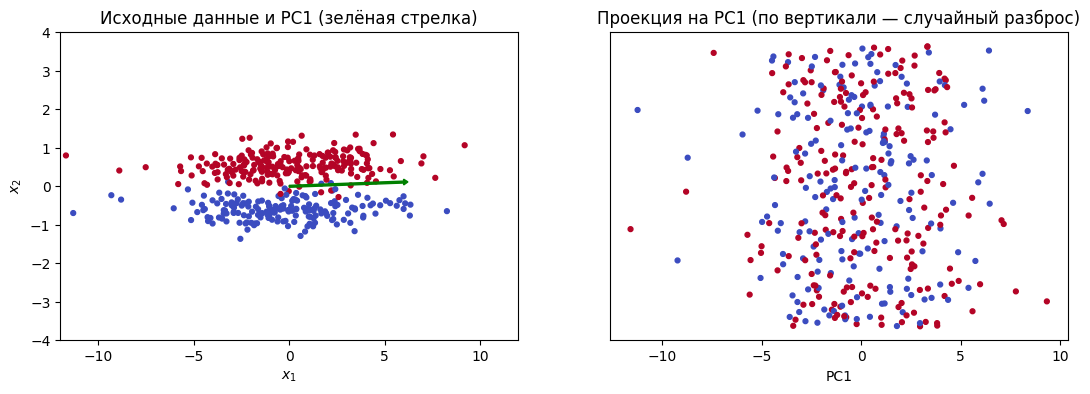

Доля дисперсии PC1: 0.958
Accuracy логистической регрессии на исходных признаках: 0.975
Accuracy на одной компоненте PC1:                     0.532


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

rng = np.random.default_rng(0)
n_obj = 400
y_cls = rng.integers(0, 2, n_obj)
x1 = rng.normal(0, 3, n_obj)                              # большой разброс, классы не различает
x2 = np.where(y_cls == 1, 0.6, -0.6) + rng.normal(0, 0.3, n_obj)   # малый разброс, но разделяет классы
X_cls = np.column_stack([x1, x2])

pca_cls = PCA(n_components=1).fit(X_cls)
T_cls = pca_cls.transform(X_cls)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(x1, x2, c=y_cls, cmap='coolwarm', s=12)
axes[0].arrow(0, 0, *(pca_cls.components_[0] * 6), width=0.05, color='green')
axes[0].set_xlabel('$x_1$'); axes[0].set_ylabel('$x_2$'); axes[0].set_title('Исходные данные и PC1 (зелёная стрелка)')
axes[0].set_ylim(-4, 4)   # обратите внимание на подписи осей: по x_1 разброс в несколько раз больше
axes[0].set_xlim(-12, 12)
axes[1].scatter(T_cls[:, 0], rng.uniform(-0.2, 0.2, n_obj), c=y_cls, cmap='coolwarm', s=12)
axes[1].set_yticks([]); axes[1].set_xlabel('PC1'); axes[1].set_title('Проекция на PC1 (по вертикали — случайный разброс)')
plt.show()

lr = LogisticRegression()
print('Доля дисперсии PC1:', pca_cls.explained_variance_ratio_[0].round(3))
print('Accuracy логистической регрессии на исходных признаках:', cross_val_score(lr, X_cls, y_cls, cv=5).mean().round(3))
print('Accuracy на одной компоненте PC1:                    ', cross_val_score(lr, T_cls, y_cls, cv=5).mean().round(3))

**Вопрос.** Почему PCA «выбросил» единственный полезный признак? Что делать в таких задачах?

<details>
<summary><b>Показать ответ</b></summary>

PCA ищет направление наибольшей дисперсии. Признак $x_1$ имеет разброс 3, а $x_2$ — около 0,67, поэтому PC1 почти совпадает с осью $x_1$ и объясняет 95,8 % дисперсии. Но классы различаются только по $x_2$. В итоге логистическая регрессия на исходных признаках даёт accuracy 0,975, а на одной PC1 — 0,532, почти как подбрасывание монеты.

PCA — метод без учителя: «важность» направления для него — это дисперсия, а не связь с целевой переменной. Что делать:
- выбирать число компонент по качеству итоговой модели на валидации, а не только по доле дисперсии;
- использовать методы с учителем: отбор признаков по связи с целевой переменной или LDA, который ищет направления, лучше всего разделяющие классы;
- не применять PCA, если признаков и так немного и модель с ними справляется.

</details>

## 6. Линейные и нелинейные данные

Сравним два набора по 500 точек: два облака и два полумесяца. Для каждого найдём одну главную компоненту и восстановим точки по ней.

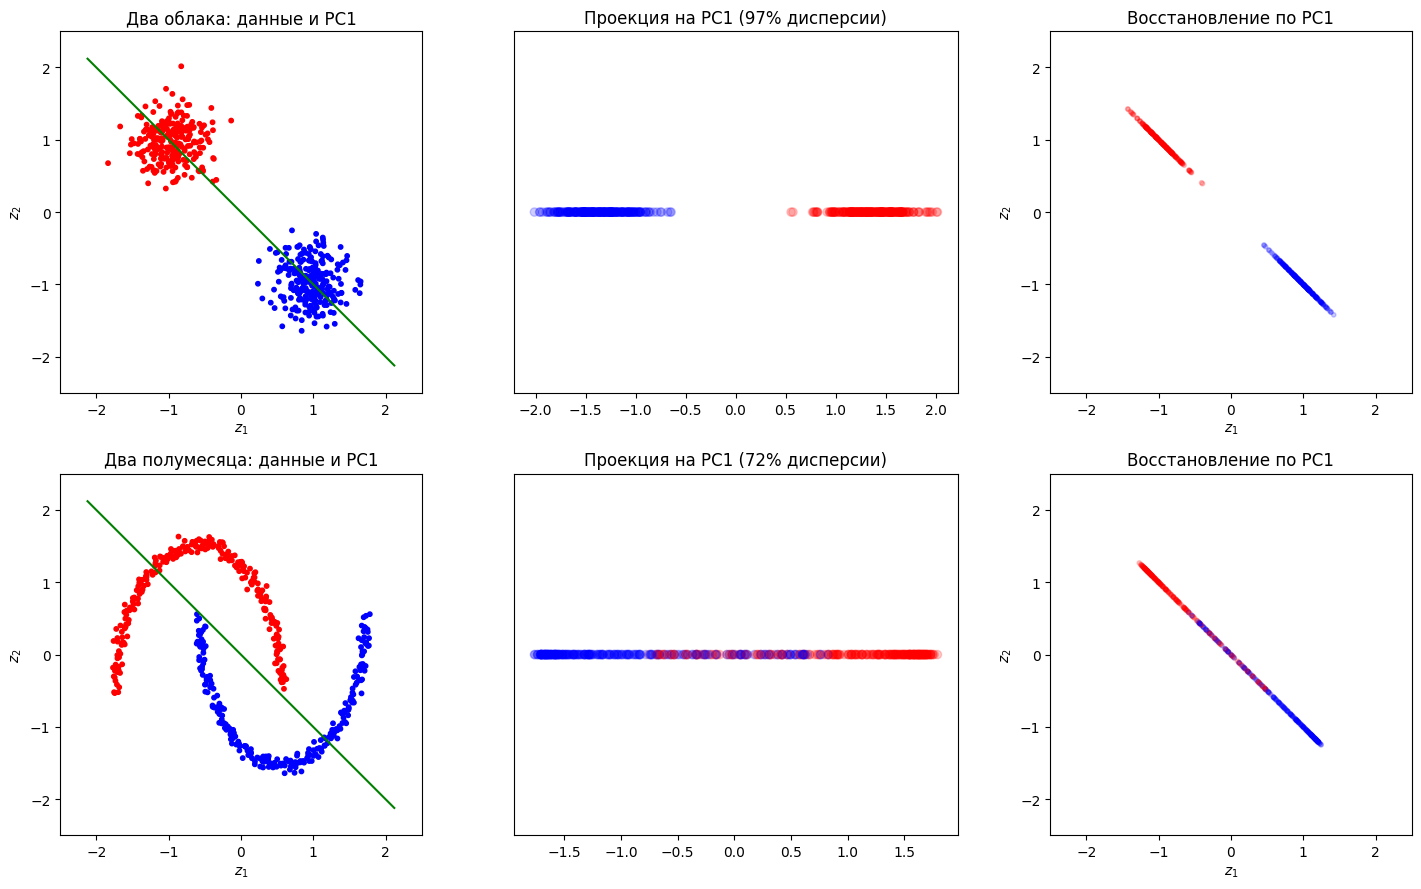

In [28]:
from sklearn.datasets import make_blobs, make_moons

sets = [('Два облака', make_blobs(n_samples=500, centers=2, random_state=42)),
        ('Два полумесяца', make_moons(n_samples=500, noise=0.03, random_state=42))]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, (name, (X_s, y_s)) in enumerate(sets):
    Z_s = StandardScaler().fit_transform(X_s)
    pca_s = PCA(n_components=1).fit(Z_s)
    T_s = pca_s.transform(Z_s)
    R_s = pca_s.inverse_transform(T_s)
    v = pca_s.components_[0]

    axes[row, 0].scatter(Z_s[:, 0], Z_s[:, 1], c=y_s, cmap='bwr_r', s=10)
    axes[row, 0].plot([-3 * v[0], 3 * v[0]], [-3 * v[1], 3 * v[1]], color='green')
    axes[row, 0].set_title(f'{name}: данные и PC1')
    axes[row, 1].scatter(T_s[:, 0], np.zeros(len(T_s)), c=y_s, cmap='bwr_r', alpha=0.2)
    axes[row, 1].set_yticks([]); axes[row, 1].set_title(f'Проекция на PC1 ({pca_s.explained_variance_ratio_[0]:.0%} дисперсии)')
    axes[row, 2].scatter(R_s[:, 0], R_s[:, 1], c=y_s, cmap='bwr_r', alpha=0.2, s=10)   # z1 против z2
    axes[row, 2].set_title('Восстановление по PC1')
    for ax in (axes[row, 0], axes[row, 2]):
        ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5); ax.set_aspect('equal')
        ax.set_xlabel('$z_1$'); ax.set_ylabel('$z_2$')
plt.tight_layout(); plt.show()

**Что мы видим.** У двух облаков первая компонента проходит через оба облака и объясняет 97 % дисперсии: на проекции классы почти не пересекаются. У полумесяцев первая компонента объясняет 72 % дисперсии, но классы на ней перекрываются: никакая прямая не передаёт изогнутую форму. Восстановленные точки в обоих случаях лежат на одной прямой — направлении PC1.

**Вопрос.** Почему у полумесяцев PC1 объясняет 72 % дисперсии, а классы на проекции всё равно перемешаны?

<details>
<summary><b>Показать ответ</b></summary>

Доля объяснённой дисперсии говорит только о том, насколько «вытянуто» облако точек вдоль прямой, а не о том, сохраняется ли нужная нам структура. Полумесяцы вместе образуют вытянутое облако, и PC1 идёт вдоль него, но классы различаются изгибом, а изгиб — нелинейная структура. Линейная проекция на одну прямую накладывает концы одного полумесяца на середину другого. Для таких данных нужны нелинейные методы: Kernel PCA и t-SNE — во второй части семинара.

</details>

## 7. Визуализация слов

Модели вроде GloVe представляют каждое слово вектором (здесь 50 чисел) так, что слова с похожим значением получают близкие векторы. Возьмём слова из нескольких смысловых групп и спроецируем их векторы на плоскость.



In [29]:
!pip install -q gensim

In [30]:
import gensim.downloader as api

glove = api.load('glove-wiki-gigaword-50')
glove['hello'][:10]

[==================================================] 100.0% 66.0/66.0MB downloaded


array([-0.38497 ,  0.80092 ,  0.064106, -0.28355 , -0.026759, -0.34532 ,
       -0.64253 , -0.11729 , -0.33257 ,  0.55243 ], dtype=float32)

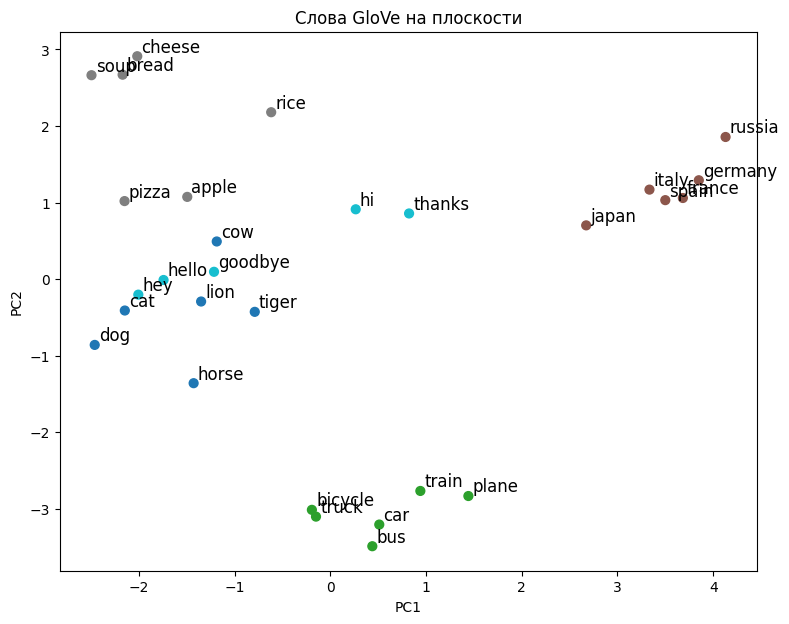

Две компоненты объясняют: 0.424


In [31]:
groups = {
    'животные': ['cat', 'dog', 'horse', 'cow', 'tiger', 'lion'],
    'транспорт': ['car', 'bus', 'train', 'truck', 'bicycle', 'plane'],
    'страны': ['france', 'germany', 'italy', 'spain', 'russia', 'japan'],
    'еда': ['bread', 'cheese', 'apple', 'rice', 'soup', 'pizza'],
    'приветствия': ['hello', 'goodbye', 'hey', 'hi', 'thanks'],
}
words = [w for g in groups.values() for w in g]
colors = [i for i, g in enumerate(groups.values()) for _ in g]
emb = np.array([glove[w] for w in words])

pca_w = PCA(n_components=2)
T_w = pca_w.fit_transform(emb)

plt.figure(figsize=(9, 7))
plt.scatter(T_w[:, 0], T_w[:, 1], c=colors, cmap='tab10', s=40)
for w, (a, b) in zip(words, T_w):
    plt.annotate(w, (a, b), fontsize=12, xytext=(3, 3), textcoords='offset points')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Слова GloVe на плоскости')
plt.show()
print('Две компоненты объясняют:', pca_w.explained_variance_ratio_.sum().round(3))

Слова из одной смысловой группы оказываются рядом, хотя PCA ничего не знает о группах: он работает только с векторами. Транспорт, страны и еда образуют отдельные кучки, а приветствия рассыпались: hello, hey и goodbye легли среди животных, hi и thanks — между группами. Две компоненты сохраняют 42,4 % дисперсии 50-мерных векторов, поэтому часть групп на плоскости накладывается.

**Вопрос.** Можно ли по этой картинке утверждать, что слово X «далеко по смыслу» от слова Y, если они далеко на плоскости? А если близко?

<details>
<summary><b>Показать ответ</b></summary>

Далеко на плоскости — значит далеко и в исходном пространстве: проекция не может увеличить расстояние между точками. Обратное неверно: две точки могут быть близки на плоскости, но различаться по отброшенным 48 компонентам. Поэтому близость на проекции — повод проверить, а не вывод. Для проверки считают расстояние (обычно косинусное) между исходными 50-мерными векторами.

</details>

## 8. Выводы

1. PCA ищет ортогональные направления наибольшей дисперсии. Это собственные векторы матрицы ковариаций, а собственные числа — дисперсии вдоль них.
2. Перед PCA данные обязательно центрируют. Стандартизуют, только если признаки в разных единицах; для пикселей это вредно.
3. Доля объяснённой дисперсии $\lambda_k / \sum \lambda_j$ помогает выбрать число компонент. Ошибка восстановления равна сумме отброшенных собственных чисел.
4. PCA сжимает данные и подавляет шум: сигнал сосредоточен в главных компонентах, шум — во всех.
5. Знак компоненты произволен. Интерпретировать компоненты можно по весам признаков, когда признаков немного и они осмысленные.
6. PCA не смотрит на целевую переменную и ищет только линейную структуру. Направление с малой дисперсией может быть самым полезным для задачи, а изогнутые структуры он не передаёт.